# Logistic Regression

The formula for the Standard Logistic Function (also known as the Sigmoid Function):$$f(x) = \frac{1}{1 + e^{-x}}$$  
The function takes any real-valued number $x$ and maps it to a value between 0 and 1.
It´s used in Machine Learning to to convert linear predictions into probabilities.  
The function logistic returns the probability given $x$

In [ ]:
import os
import urllib.request

BASE = "https://raw.githubusercontent.com/cienciadadesdsuab/DS26-27/main/Laboratoris/Session%206%20-%20Logistic%20regression%20and%20regularization/"
os.makedirs("scratch", exist_ok=True)
for f in ["P5data_linear.pkl", "scratch/linear_algebra.py"]:
    urllib.request.urlretrieve(BASE + f, f)

In [1]:
from typing import List
from matplotlib import pyplot as plt
import math
from scratch.linear_algebra import Vector, dot, vector_sum


def logistic(X) -> float:
    return 1.0/(1+np.exp(-X))

This second formula to find the derivative of the sigmoid function:

In [2]:
def logistic_prime(x: float) -> float:
    y = logistic(x)
    return y * (1 - y)

This third formula to find the cost funtion for each possible value of y:

In [3]:
import math


def _negative_log_likelihood(x: Vector, y: float, beta: Vector) -> float:
    """The negative log likelihood for one data point"""
    if y == 1:
        return -math.log(logistic(dot(x, beta)))
    else:
        return -math.log(1 - logistic(dot(x, beta)))

Let´s do the same for the whole dataset:

In [4]:
def negative_log_likelihood(xs: List[Vector],
                            ys: List[float],
                            beta: Vector) -> float:
    return sum(_negative_log_likelihood(x, y, beta) for x, y in zip(xs, ys))

Let´s find the derivative of the cost function in the logistic regression 

In [5]:
def _negative_log_partial_j(x: Vector, y: float, beta: Vector, j: int) -> float:
    """
    The j-th partial derivative for one data pont
    here i is the index of the data point
    """
    return (logistic(dot(x, beta) - y)) * x[j]

For one point

In [6]:
def _negative_log_gradient(x: Vector, y: float, beta: Vector) -> Vector:
    """
    The gradient for one data point
    """
    return [_negative_log_partial_j(x, y, beta, j)
            for j in range(len(beta))]


For the whole dataset and gets the average

In [7]:
def negative_log_gradient(xs: List[Vector],
                          ys: List[float],
                          beta: Vector) -> Vector:
    return vector_sum([_negative_log_gradient(x, y, beta)
                       for x, y in zip(xs, ys)])

**Training the model:** 

The Gradient Descent function is used to find the optimal parameters ($\mathbf{w}$) for a Logistic Regression model. The goal is to iteratively adjust the weights $\mathbf{w}$ to minimize the Log Loss (Binary Cross-Entropy) cost function

In [8]:
import numpy as np

def GradientDescent_logistic(X,y,max_iterations=10000, alpha=0.1, epsilon = 0.000001):
    m, n = X.shape # number of samples, number of features
    J = []

    # y must be a column vector of shape m x 1
    y = y.reshape(m, 1)
    
    # Create as many parameters as features and initialize them to zero
    w = np.zeros(shape=(n, 1))
    
    # Repeat for max_iterations or until we have converged
    for iteration in range(max_iterations):
        h = logistic(np.dot(X, w))#Calculates the predicted probability for every sample
        error = (h-y) # vector with the difference between the predicted probability and the true label 
        gradient = np.dot(X.T , error) / m # Calculates the average gradient across all m samples
        w = w - alpha*gradient #Updates the weight vector w 
        
        J.append( sum(-y*np.log(h)-(1-y)*np.log(1-h)) / m ) #Calculates the average Log Loss (Binary Cross-Entropy) for the current weights
        
        if (iteration > 1) and (J[-2] - J[-1]) < epsilon: #Compares the current cost J[-1] with the previous cost J[-2].
                                                          #If the reduction in cost is less than the small threshold epsilon, the model has converged
            print("Converged after {} iterations".format(iteration))
            break
            
    return [w, J]

The classifyVector function is designed to take a single data sample ($\mathbf{X}$) and its learned parameters ($\mathbf{w}$), and then use the Logistic Regression hypothesis ($\mathbf{h}(\mathbf{x})$) to predict its class label (0 or 1).

In [9]:
def classifyVector(X, w):
    '''
    Evaluate the Logistic Regression model h(x) with theta parameters,
    and returns the predicted label of x.
    '''
    prob = logistic((np.dot(X, w)))
    if prob > 0.5: return 1.0
    else: return 0.0

## Example 

Let's see how to use this code in a synthetic dataset. First load the data and plot it.

In [10]:
# Load the synthetic dataset
import pickle

with open('./P5data_linear.pkl', 'rb') as f:
    X, y = pickle.load(f)

print (X.shape)
print (y.shape)


(100, 2)
(100,)


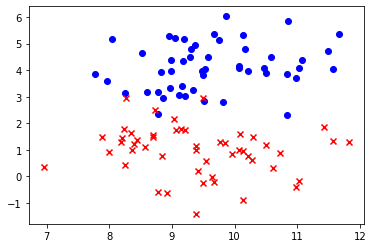

In [11]:
# Plot the data

%matplotlib inline 
import matplotlib.pyplot as plt

plt.scatter(X[y==1, 0], X[y==1, 1], marker='o', c='b') #positive samples
plt.scatter(X[y==0, 0], X[y==0, 1], marker='x', c='r') #negative samples
plt.show()

## Accuracy

Now we will prepare the data for Logistic Regression, train the model using Gradient Descent function already created and evaluate the model's performance using the **accuracy** indicator. 

$$\mathbf{Accuracy = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}}$$

In [12]:
# Append the x0 column (for the bias term w0)
m, n = X.shape # m is the number of samples and n is the number of features
ones = np.ones(shape=(m, 1))
#Xaugmented = np.append(x,X,axis=1) #The Design Matrix, which is the original data augmented with the first column of ones
Xaugmented = np.hstack( (ones, X) )

#Logistic Regression gradient descent optimization
w, J = GradientDescent_logistic(Xaugmented, y)

#Evaluate the classifier accuracy in the training data
H = [classifyVector(Xaugmented[i,:],w) for i in range(X.shape[0])] # Creates a list with probabilities for each sample
print(w)
print ("Training Accuracy :", np.sum(H == y) / m) # Accuracy 

Converged after 5271 iterations
[[-1.93509956]
 [-0.76466483]
 [ 3.57958508]]
Training Accuracy : 0.95


Let´s check now if a boundary of 0.5 makes sense or not:

## Decision Boundary

In [13]:
# Accept this function as is, you can think of it as creating a 3D surface and "cutting" it at 0.5
def plotDecisionBoundary(X, y, w):    
    #Plot data
    plt.scatter(X[y==1, 0], X[y==1, 1], marker='o', c='b') #positive samples
    plt.scatter(X[y==0, 0], X[y==0, 1], marker='x', c='r') #negative samples

    #Plot Decision Boundary
    u = np.linspace(min(X[:,0]), max(X[:,0]), 50) #vector representing the range of values for the first feature x_1
    v = np.linspace(min(X[:,1]), max(X[:,1]), 50) #vector representing the range of values for the first feature x_2
    z = np.zeros(shape=(len(u), len(v))) #predicted probability y_i for the point u_i and v_i
    for i in range(len(u)):
        for j in range(len(v)):            
            z[i, j] = logistic(np.dot(np.array([1,u[i],v[j]]),w)) # Calculate the probability for each point in the grid (50*50) 

    z = z.T #Transpose to match matplotlib convention of Y*X

    cs = plt.contour(u, v, z, levels=[0.5]) # Takes the points where the probability is 0.5 and match them to draw the line
    plt.clabel(cs, inline=1, fontsize=10)
    plt.show()

/tmp/ipykernel_291800/1360106972.py:13: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  z[i, j] = logistic(np.dot(np.array([1,u[i],v[j]]),w)) # Calculate the probability for each point in the grid (50*50)


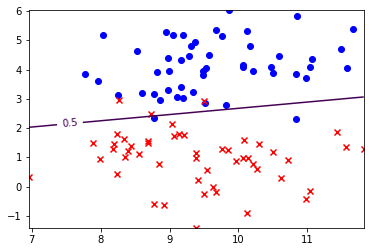

In [14]:
plotDecisionBoundary(X, y, w)

As can be seen in the previous plot the decision boundary fits reasonaby well our data, as the data is actually linearly separable. 

## Recall and Precision

**Recall** : Measures the model's ability to find all relevant cases (True Positives). 

$$\mathbf{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}} = \frac{TP}{TP + FN}$$ 

**Precision**: Measures the model's ability to be correct when it predicts the positive class. 

$$\mathbf{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}} = \frac{TP}{TP + FP}$$

In [17]:
true_positives = false_positives = true_negatives = false_negatives = 0
for x_i, y_i in zip(Xaugmented, y):
        prediction = logistic(dot(w, x_i))
    
        if y_i == 1 and prediction >= 0.5:   
            true_positives += 1
        elif y_i == 1:                      
            false_negatives += 1
        elif prediction >= 0.5:            
            false_positives += 1
        else:                              
            true_negatives += 1
    
precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)
    
    
    

print(f""" The recall for this test is: {recall}""")
print(f""" The precision for this test is: {precision}""")


 The recall for this test is: 0.96
 The precision for this test is: 0.9411764705882353
